In [84]:
import pandas as pd

df = pd.read_csv("./ia_tweets.csv")

df.head()

,ID,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_has_extended_profile,user_is_translator,user_protected,user_default_profile
0,0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,1,0,0,0
1,1,"@alvaropons Eso es imposible. Y sí, va a gener...",N,1,0,685,851,169490,128555,0,1,0,0,1
2,2,@alvaropons Lo disruptivo es que tras años de ...,NEU,1,0,685,851,169490,128555,0,1,0,0,1
3,3,"@alvaropons ¿""Prohibición del uso comercial de...",N,0,0,4877,538,6123,3156,0,1,0,0,0
4,4,@santoroydonoso Cómo se está estudiando prohib...,NEU,0,0,15936,2395,66945,68578,0,1,0,0,0


In [85]:
df.dtypes

ID                           int64
text                           str
polarity                       str
favorite_count               int64
retweet_count                int64
user_followers_count         int64
user_friends_count           int64
user_favourites_count        int64
user_statuses_count          int64
user_verified                int64
user_has_extended_profile    int64
user_is_translator           int64
user_protected               int64
user_default_profile         int64
dtype: object

In [86]:
def filtrar_por_polaridad(field):
    return df[df["polarity"] == field]

cant_negativos = len(filtrar_por_polaridad("N"))
cant_neutros = len(filtrar_por_polaridad("NEU"))
cant_positivos =  len(filtrar_por_polaridad("P"))

print('Cantidad de tweets: ', len(df["ID"]))
print('Tweets Negativos: ', cant_negativos, ', Neutros' , cant_neutros,', Positivos', cant_positivos)

# Cantidad de datos desbalanceada, se tiene mucho mas datos neutros que negativos o positivos.

Cantidad de tweets:  4038
Tweets Negativos:  592 , Neutros 2689 , Positivos 757


In [87]:
cantidad_na = df.isna().sum()
print(cantidad_na)

#(cantidad_negativos_columna("favorite_count"))

# No hay nulls o valores

ID                           0
text                         0
polarity                     0
favorite_count               0
retweet_count                0
user_followers_count         0
user_friends_count           0
user_favourites_count        0
user_statuses_count          0
user_verified                0
user_has_extended_profile    0
user_is_translator           0
user_protected               0
user_default_profile         0
dtype: int64


In [88]:
cantidad_negativos = (df.select_dtypes(include='number') < 0).sum()
print(cantidad_negativos)

ID                           0
favorite_count               0
retweet_count                0
user_followers_count         0
user_friends_count           0
user_favourites_count        0
user_statuses_count          0
user_verified                0
user_has_extended_profile    0
user_is_translator           0
user_protected               0
user_default_profile         0
dtype: int64


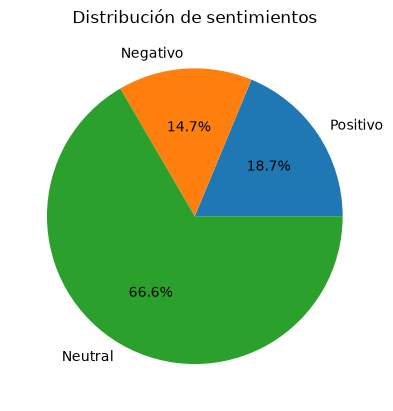

In [89]:
import matplotlib.pyplot as plt

# Datos
clases = ['Positivo', 'Negativo', 'Neutral']
cantidades = [cant_positivos, cant_negativos, cant_neutros]

# Crear gráfico
plt.pie(cantidades, labels=clases, autopct='%1.1f%%')
plt.title('Distribución de sentimientos')
plt.show()

3.815998018821199
2243
0


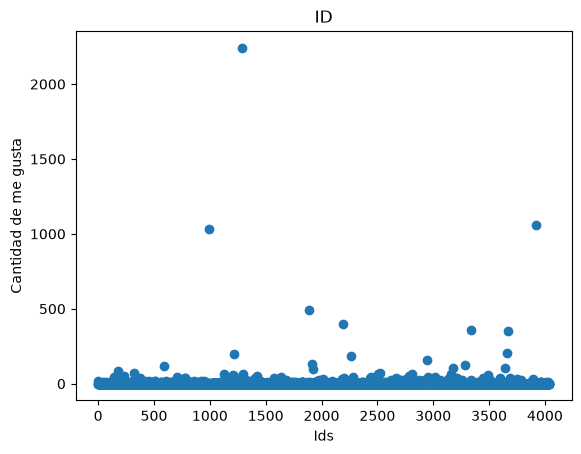

In [90]:
print(df["favorite_count"].mean())
print(df["favorite_count"].max())
print(df["favorite_count"].min())

plt.scatter(df['ID'], df['favorite_count'])

plt.xlabel('Ids')
plt.ylabel('Cantidad de me gusta')
plt.title('ID')

plt.show()

0.8749380881624567
502
0


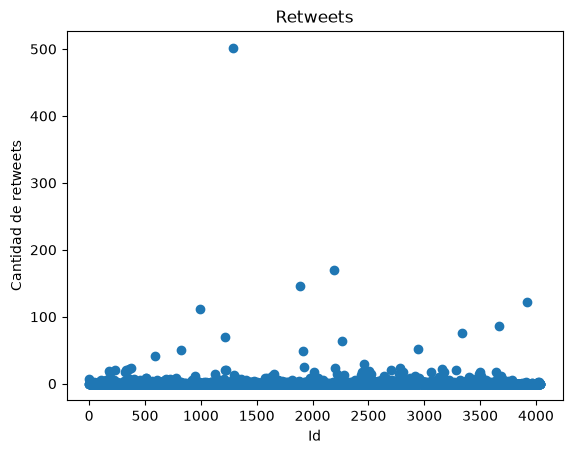

In [91]:
print(df["retweet_count"].mean())
print(df["retweet_count"].max())
print(df["retweet_count"].min())

plt.scatter(df['ID'], df['retweet_count'])

plt.xlabel('Id')
plt.ylabel('Cantidad de retweets')
plt.title('Retweets')

plt.show()

Cantidad de tweets positivo con interaccion:  180
Cantidad de tweets negativos con interaccion:  142
Media de interacciones en positivos:  6.220607661822985
Media de interacciones en negativos:  3.6503378378378377


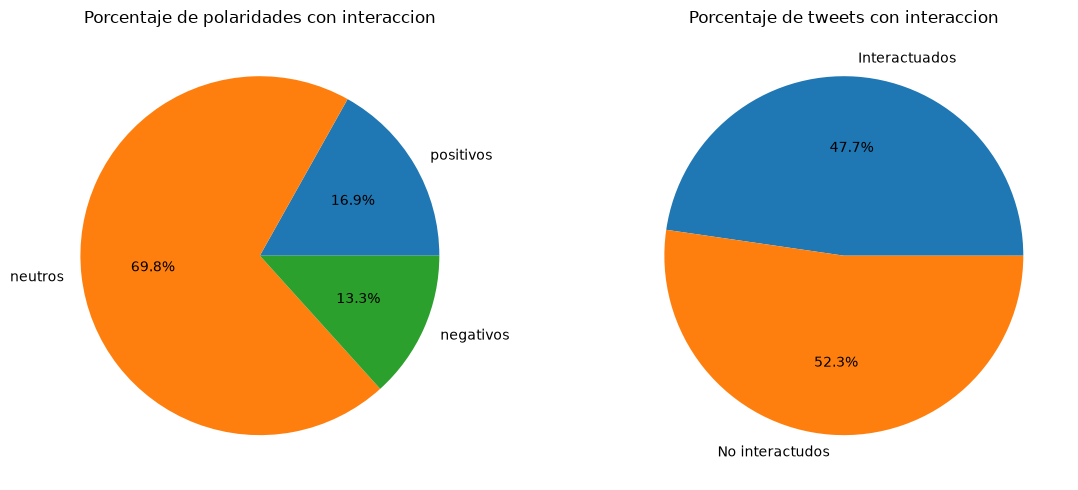

In [93]:
df['tweet_interactions'] = df['favorite_count'] + df['retweet_count']

tweets_con_interaccion = (df['tweet_interactions'] > 0).sum()
tweets_sin_interaccion = (df['tweet_interactions'] == 0).sum()

positivos_con_interaccion = (df[df['polarity'] == 'P']['tweet_interactions'] > 1).sum()
neutros_con_interaccion = (df[df['polarity'] == 'NEU']['tweet_interactions'] > 1).sum()
negativos_con_interaccion = (df[df['polarity'] == 'N']['tweet_interactions'] > 1).sum()
interaccion_positivos_media = df[df['polarity'] == 'P']['tweet_interactions'].mean()
interaccion_negativos_media = df[df['polarity'] == 'N']['tweet_interactions'].mean()

print("Cantidad de tweets positivo con interaccion: ", positivos_con_interaccion)
print("Cantidad de tweets negativos con interaccion: ", negativos_con_interaccion)
print("Media de interacciones en positivos: ", interaccion_positivos_media)
print("Media de interacciones en negativos: ", interaccion_negativos_media)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].pie([positivos_con_interaccion, neutros_con_interaccion, negativos_con_interaccion], labels=["positivos", "neutros", "negativos"], autopct='%1.1f%%')
ax[0].set_title('Porcentaje de polaridades con interaccion')

ax[1].pie([tweets_con_interaccion, tweets_sin_interaccion],
  labels=["Interactuados", "No interactudos"], autopct='%1.1f%%')
ax[1].set_title('Porcentaje de tweets con interaccion')

plt.tight_layout()
plt.show()